# Task 04 – Customer Segmentation, Churn-Risk Scoring and Recommendation Model

**EdVyro Data Analytics Internship · Task 04: Segmentation and Recommendation Model**
Author: Poorvansh · Domain: Data Analytics

> **Dataset notice:** As in the earlier tasks of this project, the analysis uses the public IBM Telco Customer Churn sample because the EdVyro resource files were unavailable. It is not an EdVyro-provided dataset.

**Contents**
1. Project Introduction · 2. Business Problem · 3. Dataset Overview · 4. Data Loading · 5. Data Quality Validation · 6. Feature Selection · 7. Feature Engineering · 8. Customer Segmentation · 9. Segment Analysis · 10. Churn Risk Scoring · 11. Risk Category Distribution · 12. Recommendation Engine · 13. Business Insights · 14. Edge Case Validation · 15. Final Conclusion

## 1. Project Introduction

The earlier tasks in this repository cleaned the data and described **where** churn is concentrated (by contract, payment method and tenure). This notebook moves from description to **prioritisation**: it answers *which customers should the retention team contact first, and with what kind of offer?*

The work produces three connected pieces:

| Piece | What it answers | How it is built |
| --- | --- | --- |
| **Customer segments** | *Who is this customer?* (lifecycle stage, value, plan, commitment) | Five ordered, rule-based business segments |
| **Churn-risk score (0–100)** | *How likely is this customer to leave, relative to others?* | A transparent points scorecard with eight yes/no indicators |
| **Recommendation engine** | *What should we do, and how urgently?* | Segment decides the **content** of the action, risk tier decides the **urgency** |

Everything is reproducible: the business logic lives in `scripts/segmentation_model.py`, random steps use a fixed seed, and every number in the outputs is calculated from the dataset.

## 2. Business Problem

A subscription business cannot give every customer the same retention effort. Retention budgets are limited, so the team needs a **ranked, explainable list**: a person reading a customer's record should be able to see *why* that customer was flagged.

Objectives:
1. Choose useful behavioural and account features.
2. Create understandable customer segments.
3. Build a reproducible churn-risk score, validate it, and test edge cases.
4. Turn segments and risk levels into specific retention actions.

**Three different things – kept separate throughout this notebook**

| Term | Meaning | Used for |
| --- | --- | --- |
| **Historical churn status** (`Churn`) | Whether the customer had left when the data was recorded | Describing segments; setting indicator weights on the *training* split; validating on the *test* split |
| **Rule-based churn-risk score** | 0–100 points from eight transparent indicators. **Not a trained predictive model.** It never takes `Churn` as an input. | Prioritising customers |
| **Benchmark model probability** | Output of a logistic regression fitted on the training split | Only a yardstick for the score's ranking quality – not exported or used for decisions |

## 3. Dataset Overview

- **Source:** IBM `telco-customer-churn-on-icp4d` public sample (see the project README for the URL and checksum).
- **Grain:** one row per customer, identified by `customerID`.
- **Input file:** `data/processed/customer_churn_cleaned.csv`, produced by `scripts/analyze_customer_churn.py` in the earlier task. The raw file in `data/raw/` stays unchanged.
- **Field groups:**
  - *Account:* `tenure` (months), `Contract`, `PaymentMethod`, `PaperlessBilling`, `MonthlyCharges`, `TotalCharges`
  - *Services:* `PhoneService`, `MultipleLines`, `InternetService` and six add-ons (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`)
  - *Demographics:* `gender`, `SeniorCitizen`, `Partner`, `Dependents`
  - *Outcome:* `Churn` (`Yes`/`No`)
- The file is a single snapshot with no dates, so "risk" here means *resemblance to customers who churned*, not a forecast for a specific future period.

## 4. Data Loading

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Locate the project root whether Jupyter was started in the root or in notebooks/.
PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data" / "processed" / "customer_churn_cleaned.csv").exists()
)
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import segmentation_model as sm          # all segmentation / scoring / recommendation rules
import validate_edge_cases as edge_cases  # edge-case test suite (Section 14)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "customer_churn_cleaned.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
VISUALS_DIR = OUTPUT_DIR / "visuals"
VISUALS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)
print("Project root:", PROJECT_ROOT.name)

Project root: customer-churn-analysis


In [2]:
# Shared chart style: one calm blue for single-series bars, an ordered light-to-dark
# blue ramp for the ordered risk tiers, recessive grid and axes.
SURFACE, INK, INK_SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BAR_COLOR, BOX_FILL, BOX_EDGE = "#2a78d6", "#b7d3f6", "#1c5cab"
RISK_COLORS = {"Low": "#86b6ef", "Medium": "#3987e5", "High": "#1c5cab", "Critical": "#0d366b"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SECONDARY, "axes.labelsize": 11,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "xtick.labelsize": 10.5, "ytick.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 11,
})


def new_chart(title, subtitle, figsize=(10, 4.8)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=INK, pad=30)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10.5, color=INK_SECONDARY, va="bottom")
    return fig, ax


def save_chart(fig, filename):
    fig.tight_layout()
    fig.savefig(VISUALS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved outputs/visuals/{filename}")


VALUE_LABEL_BOX = {"facecolor": SURFACE, "edgecolor": "none", "pad": 1}


def reference_line(ax, value, label, horizontal_bars=True):
    # Dashed line for an overall average, labelled directly instead of with a legend.
    if horizontal_bars:
        ax.set_ylim(-1.0, len(ax.get_yticks()) - 0.5)  # room for the label below the bars
        ax.axvline(value, color=INK_SECONDARY, linestyle="--", linewidth=1.2, zorder=1)
        ax.text(value, -0.72, f" {label}", color=INK_SECONDARY, fontsize=9.5, va="center")
    else:
        ax.axhline(value, color=INK_SECONDARY, linestyle="--", linewidth=1.2)
        ax.text(-0.45, value, f"{label} ", color=INK_SECONDARY, fontsize=9.5, va="bottom")

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from {DATA_PATH.relative_to(PROJECT_ROOT)}")
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame().T)

Loaded 7,043 rows x 21 columns from data/processed/customer_churn_cleaned.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,str


## 5. Data Quality Validation

The cleaned file was already validated in the earlier task. Because this notebook builds a decision tool on top of it, the key checks are repeated here, and the data is then passed through `sm.prepare_customers()` – the same validation step that protects the pipeline against bad records (Section 14 tests it with deliberately broken data).

In [4]:
def iqr_flags(series):
    # 1.5 x IQR rule: a screening aid for extreme values, not proof of an error.
    q1, q3 = series.quantile([0.25, 0.75])
    return int(((series < q1 - 1.5 * (q3 - q1)) | (series > q3 + 1.5 * (q3 - q1))).sum())


domain_violations = sum(
    int((~raw[column].isin(allowed)).sum()) for column, allowed in sm.CATEGORY_DOMAINS.items()
)
quality_checks = pd.DataFrame([
    ("Rows", f"{len(raw):,}"),
    ("Unique customer IDs", f"{raw['customerID'].nunique():,}"),
    ("Exact duplicate rows", int(raw.duplicated().sum())),
    ("Missing values (all columns)", int(raw.isna().sum().sum())),
    ("Category values outside expected domains", domain_violations),
    ("Tenure range (months)", f"{raw['tenure'].min()} to {raw['tenure'].max()}"),
    ("MonthlyCharges range", f"{raw['MonthlyCharges'].min():.2f} to {raw['MonthlyCharges'].max():.2f}"),
    ("Customers with tenure = 0", int(raw['tenure'].eq(0).sum())),
    ("TotalCharges for tenure = 0 customers", sorted(raw.loc[raw['tenure'].eq(0), 'TotalCharges'].unique().tolist())),
    ("Customers with MonthlyCharges = 0", int(raw['MonthlyCharges'].eq(0).sum())),
    ("IQR outliers: tenure / MonthlyCharges", f"{iqr_flags(raw['tenure'])} / {iqr_flags(raw['MonthlyCharges'])}"),
], columns=["check", "result"])
display(quality_checks)

customers, issue_log = sm.prepare_customers(raw)
print(f"Records after pipeline validation: {len(customers):,} | issues logged: {len(issue_log)}")
assert len(customers) == len(raw) and customers["customerID"].is_unique
assert sm.has_sufficient_data(customers).all(), "Every cleaned customer should be scorable"

,check,result
0,Rows,"7,043"
1,Unique customer IDs,"7,043"
2,Exact duplicate rows,0
3,Missing values (all columns),0
4,Category values outside expected domains,0
5,Tenure range (months),0 to 72
6,MonthlyCharges range,18.25 to 118.75
7,Customers with tenure = 0,11
8,TotalCharges for tenure = 0 customers,[0.0]
9,Customers with MonthlyCharges = 0,0


Records after pipeline validation: 7,043 | issues logged: 0


**Result:** the cleaned data has no missing values, duplicates or out-of-domain categories, and no IQR outliers in tenure or monthly charges. The 11 zero-tenure customers carry `TotalCharges = 0`, a documented imputation from the earlier task; they are valid new customers and stay in the analysis. Every customer has enough information to be segmented and scored.

## 6. Feature Selection

Features were chosen for being **behavioural or account-related, actionable, and available for every customer**. Evidence from the earlier EDA (`reports/data_quality_report.md`) showed large churn differences by contract, payment method and tenure.

| Feature | Used for | Why it was selected |
| --- | --- | --- |
| `tenure` | Segments + risk | Lifecycle stage; first-year customers churned far more often (47.4% for 0–12 months in the EDA) |
| `Contract` | Segments + risk | Month-to-month customers can leave any month (42.7% churn vs 2.8% on two-year contracts) |
| `MonthlyCharges` | Segments + risk | Revenue at stake, and price pressure |
| `InternetService` | Segments + risk | Separates phone-only customers; fiber customers behave differently |
| `PaymentMethod` | Risk | Electronic check had the highest churn (45.3%); it is a manual, non-automatic method |
| `OnlineSecurity`, `TechSupport` | Risk | Protective/support add-ons; easy to act on through trials and bundles |
| `PaperlessBilling` | Risk | Account behaviour available for every customer |
| Six add-on services | Profile (`addon_services` count) | Depth of the relationship |
| `Churn` | Weights (training split) + validation only | Outcome – never an input to a segment or score |

**Deliberately excluded**

| Feature | Reason |
| --- | --- |
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Demographic, not actionable, and scoring on them could lead to unfair treatment of customer groups |
| `TotalCharges` | Approximately `tenure × MonthlyCharges`, so it repeats information already used |
| `customerID` | Identifier only |
| `PhoneService`, `MultipleLines`, streaming / backup / device add-ons | Weak or indirect signals; captured through the add-on count instead |

## 7. Feature Engineering

Three things are engineered from the selected fields:

1. **`addon_services`** – how many of the six optional add-ons a customer has (0–6).
2. **Business thresholds** – set from feature distributions or the contract calendar, **not** from churn:
   - *Early tenure:* 12 months or less (the first contract year).
   - *High monthly charge:* 90 or more, which is about the 75th percentile of `MonthlyCharges` (checked below).
3. **Eight yes/no risk indicators** (1 = present). If an input is unknown the flag stays 0, so missing data can never *add* risk.

In [5]:
customers["addon_services"] = sm.count_addon_services(customers)

monthly_quartiles = customers["MonthlyCharges"].quantile([0.25, 0.50, 0.75]).round(2)
print("MonthlyCharges quartiles:", monthly_quartiles.to_dict())
print(f"High-charge threshold used: {sm.HIGH_MONTHLY_CHARGE:.0f} "
      f"(75th percentile = {monthly_quartiles[0.75]:.2f})")

indicators = sm.compute_risk_indicators(customers)
indicator_prevalence = pd.DataFrame({
    "definition": pd.Series(sm.RISK_INDICATORS),
    "customers_flagged": indicators.sum(),
    "share_of_customers_pct": (indicators.mean() * 100).round(1),
})
display(indicator_prevalence)

MonthlyCharges quartiles: {0.25: 35.5, 0.5: 70.35, 0.75: 89.85}
High-charge threshold used: 90 (75th percentile = 89.85)


,definition,customers_flagged,share_of_customers_pct
month_to_month_contract,Contract is month-to-month (customer can leave in any month),3875,55.0
early_tenure,Tenure of 12 months or less (first contract year),2186,31.0
electronic_check_payment,"Pays by electronic check (manual, non-automatic payment)",2365,33.6
fiber_optic_service,Has fiber optic internet service,3096,44.0
no_online_security,Internet customer without the Online Security add-on,3498,49.7
no_tech_support,Internet customer without the Tech Support add-on,3473,49.3
high_monthly_charges,Monthly charges of 90 or more,1744,24.8
paperless_billing,Uses paperless billing,4171,59.2


## 8. Customer Segmentation

### 8.1 Rule-based segments

Customers are placed into **five mutually exclusive segments** using ordered business rules – the first rule a customer matches decides the segment. Customers whose tenure or contract is missing go to a separate *Needs Data Review* group instead of being guessed (none in this dataset).

Why this order? Lifecycle stage comes first because a first-year customer needs onboarding whatever they spend. Among established customers, high spend comes next because those accounts carry the most revenue. Phone-only customers are then separated because their needs are so different, and the remaining customers split by whether they have committed to a contract.

**Mapping to the suggested categories in the task brief:** *New*, *High-Value* and *Loyal* exist as segments. *Price-Sensitive* is not used as a label because the data does not record price sensitivity; the nearest observable group is the low-cost **Phone-Only Basic** plan, named for what customers buy. *At-Risk* and *High-Risk* are represented by the **risk tiers** in Section 10 rather than as segments, so that "who the customer is" and "how likely they are to leave" are not mixed up and the same indicators are not counted twice.

In [6]:
segment_rules = pd.DataFrame(sm.SEGMENTS).rename(columns={"name": "segment", "rule": "assignment rule", "why": "business meaning"})
segment_rules.index = range(1, len(segment_rules) + 1)
segment_rules.index.name = "priority"
display(segment_rules)

customers["segment"] = sm.assign_segments(customers)
assert customers["segment"].isin(sm.SEGMENT_ORDER).all(), "Every valid customer must get a business segment"

segment_counts = customers["segment"].value_counts().reindex(sm.SEGMENT_ORDER)
display(pd.DataFrame({
    "customers": segment_counts,
    "share_pct": (segment_counts / len(customers) * 100).round(1),
}))

,segment,assignment rule,business meaning
priority,,,
1,New Customers,Tenure of 12 months or less,The first year is the onboarding period; lifecycle stage matters more than spend here.
2,High-Value Customers,Tenure above 12 months and monthly charges of 90 or more,The top quarter of monthly spend; each lost customer removes the most recurring revenue.
3,Phone-Only Basic Customers,Tenure above 12 months and no internet service,Buy only the low-cost phone plan; very different needs from internet customers.
4,Loyal Contract Customers,Tenure above 12 months on a one- or two-year contract,Established customers who have already committed to a fixed term.
5,Flexible Month-to-Month Customers,Tenure above 12 months on a month-to-month contract,"Established customers with no fixed term, so they can leave in any month."


,customers,share_pct
segment,,
New Customers,2186,31.0
High-Value Customers,1525,21.7
Phone-Only Basic Customers,1013,14.4
Loyal Contract Customers,1221,17.3
Flexible Month-to-Month Customers,1098,15.6


### 8.2 Would K-Means clustering do better?

The brief asks to evaluate clustering where appropriate. K-Means is run on four standardised account features (tenure, monthly charges, number of add-ons, contract length). The **silhouette score** measures how well separated the clusters are (–1 to 1; values near 0 mean overlapping groups, values above about 0.5 mean clearly separated groups).

In [7]:
cluster_features = pd.DataFrame({
    "tenure": customers["tenure"],
    "MonthlyCharges": customers["MonthlyCharges"],
    "addon_services": customers["addon_services"],
    "contract_months": customers["Contract"].map({"Month-to-month": 0, "One year": 12, "Two year": 24}),
})
scaled = StandardScaler().fit_transform(cluster_features)

silhouette = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=sm.RANDOM_SEED).fit(scaled)
    silhouette[k] = round(silhouette_score(scaled, model.labels_), 3)
silhouette_table = pd.Series(silhouette, name="silhouette_score").rename_axis("k").to_frame()
display(silhouette_table.T)

best_k = int(silhouette_table["silhouette_score"].idxmax())
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=sm.RANDOM_SEED).fit(scaled)
customers["kmeans_cluster"] = kmeans.labels_
cluster_profile = customers.groupby("kmeans_cluster").agg(
    customers=("customerID", "size"),
    avg_tenure=("tenure", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_addons=("addon_services", "mean"),
    month_to_month_pct=("Contract", lambda s: s.eq("Month-to-month").mean() * 100),
).round(1)
print(f"Best k by silhouette: {best_k} (score {silhouette[best_k]})")
display(cluster_profile)
display(pd.crosstab(customers["segment"], customers["kmeans_cluster"]).reindex(sm.SEGMENT_ORDER))

k,2,3,4,5,6,7,8
silhouette_score,0.365,0.403,0.362,0.344,0.34,0.335,0.34


Best k by silhouette: 3 (score 0.403)


,customers,avg_tenure,avg_monthly_charges,avg_addons,month_to_month_pct
kmeans_cluster,,,,,
0,2232,56.3,88.7,4.1,17.7
1,1165,42.0,24.5,0.2,0.6
2,3646,14.6,63.0,1.3,95.3


kmeans_cluster,0,1,2
segment,,,
New Customers,20,134,2032
High-Value Customers,1186,0,339
Phone-Only Basic Customers,0,883,130
Loyal Contract Customers,948,147,126
Flexible Month-to-Month Customers,78,1,1019


**Decision: keep the rule-based segments.** The best silhouette score is only moderate, so the data does not split into sharply separated natural groups. The K-Means clusters mostly recover the same dimensions as the business rules (tenure, spend and contract), but:

- a cluster is defined by a centre point, not a rule, so a stakeholder cannot tell from a customer's record which cluster they belong to;
- cluster boundaries move whenever the data is refreshed or rescaled;
- the rules separate groups the business treats differently (for example phone-only customers versus high-spend internet customers) and stay identical on every run.

K-Means therefore adds no value that justifies losing explainability. It is kept here only as a cross-check.

## 9. Segment Analysis

Historical churn is used here only to *describe* the segments – it played no part in assigning them.

In [8]:
segment_profile = customers.groupby("segment").agg(
    customers=("customerID", "size"),
    avg_tenure_months=("tenure", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_addon_services=("addon_services", "mean"),
    month_to_month_pct=("Contract", lambda s: s.eq("Month-to-month").mean() * 100),
    fiber_optic_pct=("InternetService", lambda s: s.eq("Fiber optic").mean() * 100),
    electronic_check_pct=("PaymentMethod", lambda s: s.eq("Electronic check").mean() * 100),
    historical_churn_rate_pct=("Churn", sm.churn_rate_pct),
).reindex(sm.SEGMENT_ORDER)
segment_profile.insert(1, "customer_pct", segment_profile["customers"] / len(customers) * 100)
overall_churn = sm.churn_rate_pct(customers["Churn"])
display(segment_profile.round(1))
print(f"Overall historical churn rate: {overall_churn:.2f}%")

,customers,customer_pct,avg_tenure_months,avg_monthly_charges,avg_addon_services,month_to_month_pct,fiber_optic_pct,electronic_check_pct,historical_churn_rate_pct
segment,,,,,,,,,
New Customers,2186,31.0,4.7,56.1,1.0,91.2,42.2,44.7,47.4
High-Value Customers,1525,21.7,50.3,101.6,3.9,42.4,96.9,42.2,26.7
Phone-Only Basic Customers,1013,14.4,43.7,21.4,0.0,13.4,0.0,7.1,2.1
Loyal Contract Customers,1221,17.3,51.8,67.6,3.5,0.0,10.6,15.8,5.7
Flexible Month-to-Month Customers,1098,15.6,30.4,67.6,1.7,100.0,51.5,43.6,30.5


Overall historical churn rate: 26.54%


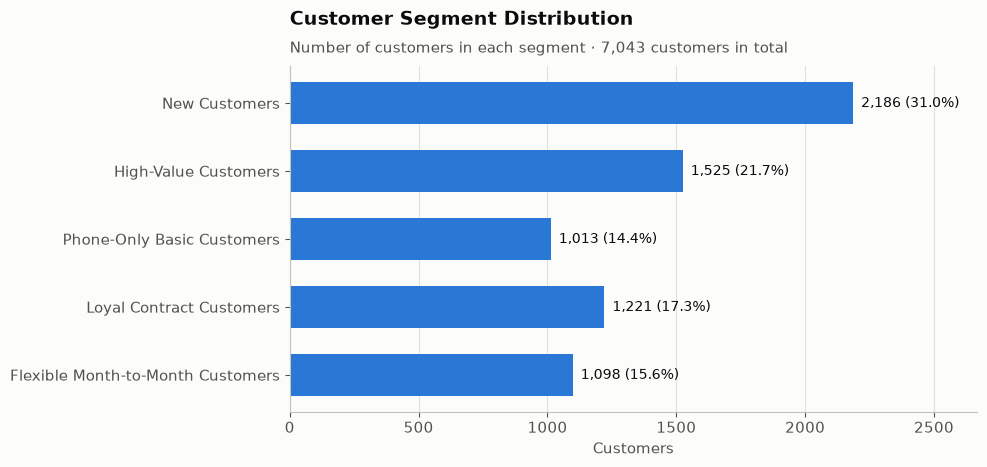

Saved outputs/visuals/01_segment_distribution.png


In [9]:
# Chart 1 - Customer segment distribution
fig, ax = new_chart("Customer Segment Distribution",
                    f"Number of customers in each segment · {len(customers):,} customers in total")
order = sm.SEGMENT_ORDER[::-1]
ax.barh(order, segment_profile.loc[order, "customers"], color=BAR_COLOR, height=0.62)
for y, name in enumerate(order):
    count, pct = segment_profile.loc[name, ["customers", "customer_pct"]]
    ax.text(count, y, f"  {count:,.0f} ({pct:.1f}%)", va="center", color=INK, fontsize=10)
ax.set_xlabel("Customers")
ax.set_xlim(0, segment_profile["customers"].max() * 1.22)
ax.grid(axis="x"); ax.set_axisbelow(True)
save_chart(fig, "01_segment_distribution.png")

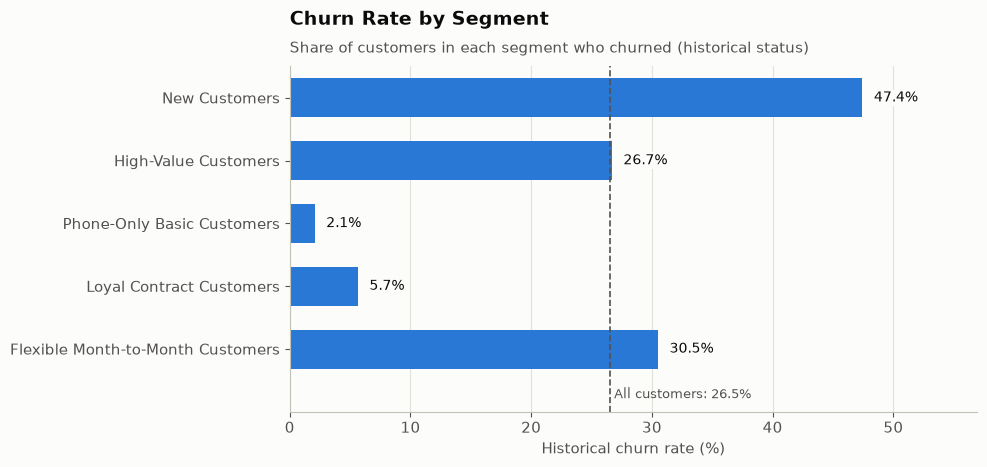

Saved outputs/visuals/02_churn_rate_by_segment.png


In [10]:
# Chart 2 - Historical churn rate by segment, with the overall rate as reference
fig, ax = new_chart("Churn Rate by Segment",
                    "Share of customers in each segment who churned (historical status)")
rates = segment_profile.loc[order, "historical_churn_rate_pct"]
ax.barh(order, rates, color=BAR_COLOR, height=0.62)
for y, value in enumerate(rates):
    ax.text(value + rates.max() * 0.02, y, f"{value:.1f}%", va="center", color=INK, fontsize=10,
            bbox=VALUE_LABEL_BOX, zorder=3)
reference_line(ax, overall_churn, f"All customers: {overall_churn:.1f}%")
ax.set_xlabel("Historical churn rate (%)")
ax.set_xlim(0, rates.max() * 1.2)
ax.grid(axis="x"); ax.set_axisbelow(True)
save_chart(fig, "02_churn_rate_by_segment.png")

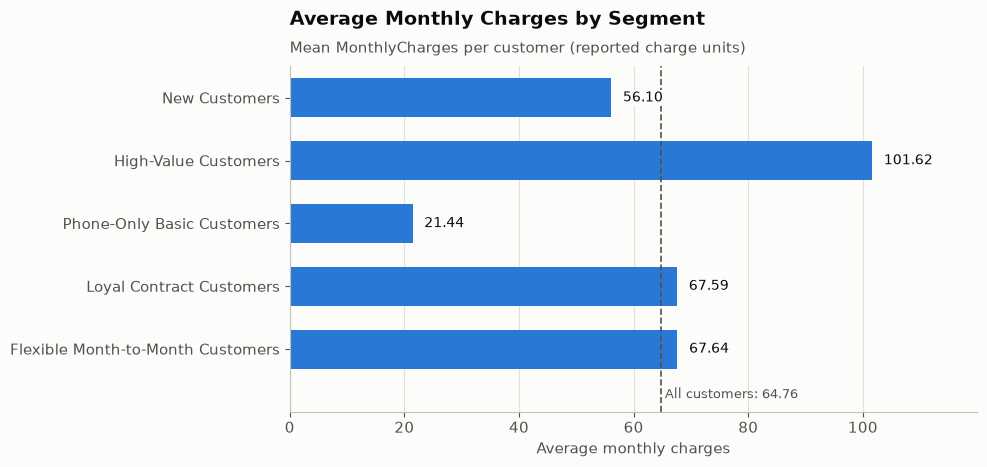

Saved outputs/visuals/04_avg_monthly_charges_by_segment.png


In [11]:
# Chart 4 - Average monthly charges by segment
overall_monthly = customers["MonthlyCharges"].mean()
fig, ax = new_chart("Average Monthly Charges by Segment",
                    "Mean MonthlyCharges per customer (reported charge units)")
charges = segment_profile.loc[order, "avg_monthly_charges"]
ax.barh(order, charges, color=BAR_COLOR, height=0.62)
for y, value in enumerate(charges):
    ax.text(value + charges.max() * 0.02, y, f"{value:.2f}", va="center", color=INK, fontsize=10,
            bbox=VALUE_LABEL_BOX, zorder=3)
reference_line(ax, overall_monthly, f"All customers: {overall_monthly:.2f}")
ax.set_xlabel("Average monthly charges")
ax.set_xlim(0, charges.max() * 1.18)
ax.grid(axis="x"); ax.set_axisbelow(True)
save_chart(fig, "04_avg_monthly_charges_by_segment.png")

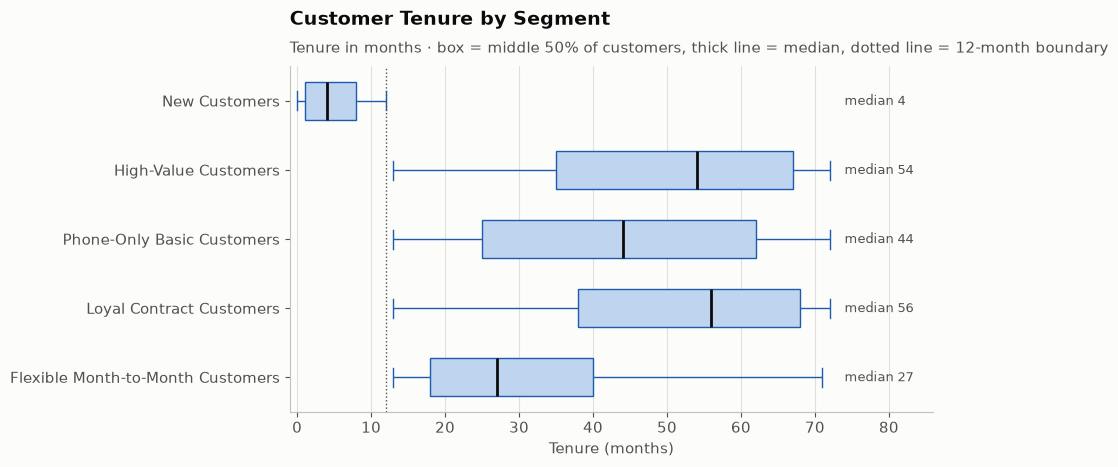

Saved outputs/visuals/05_tenure_by_segment.png


In [12]:
# Chart 5 - Tenure distribution by segment (box = middle 50% of customers, line = median)
fig, ax = new_chart("Customer Tenure by Segment",
                    "Tenure in months · box = middle 50% of customers, thick line = median, dotted line = 12-month boundary")
sns.boxplot(
    data=customers, y="segment", x="tenure", order=sm.SEGMENT_ORDER, ax=ax, width=0.55,
    color=BOX_FILL, linecolor=BOX_EDGE, medianprops={"color": INK, "linewidth": 2},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": MUTED},
)
medians = customers.groupby("segment")["tenure"].median()
for y, name in enumerate(sm.SEGMENT_ORDER):
    ax.text(74, y, f"median {medians[name]:.0f}", va="center", color=INK_SECONDARY, fontsize=9.5)
ax.axvline(sm.EARLY_TENURE_MONTHS, color=INK_SECONDARY, linestyle=":", linewidth=1)
ax.set_xlim(-1, 86)
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("")
ax.grid(axis="x"); ax.set_axisbelow(True)
save_chart(fig, "05_tenure_by_segment.png")

**What the segments show**

- **New Customers** are the largest segment and churned most often: almost all are on month-to-month terms and they have few add-ons (about one on average). The onboarding period is the most exposed stage of the relationship.
- **High-Value Customers** pay the most per month and are mostly fiber customers with several add-ons. Their churn rate is close to the overall average, but the segment mixes month-to-month and contract customers – Section 13 shows how differently those two halves behave.
- **Phone-Only Basic Customers** pay the least and are the most stable group.
- **Loyal Contract Customers** combine long tenure with fixed-term contracts and have a very low churn rate.
- **Flexible Month-to-Month Customers** have stayed beyond a year without committing; their churn rate is above the overall average despite the longer tenure.

## 10. Churn Risk Scoring

### 10.1 Method

1. **Split before learning anything from churn.** Customers are split 70% / 30% into training and test sets (stratified by churn, seed 42). Only the training set is used to set weights; the test set is kept aside for an honest check (no data leakage).
2. **Measure each indicator on the training set.** *Lift* = churn rate when the indicator is present minus churn rate when it is absent, in percentage points.
3. **Assign points.** Indicators with a lift below 5 points get 0 points. The rest share **100 points** in proportion to their lift (rounded to whole points).
4. **Score each customer.** `risk_score = (points from the customer's indicators ÷ maximum possible points) × 100`, so the score is always between 0 and 100.
5. **Assign a risk category:** Low 0–29 · Medium 30–59 · High 60–79 · Critical 80–100 (the task's suggested thresholds; Section 10.2 checks that churn rises across them).

This is a **points scorecard, not a machine-learning model**: the weights are simple, visible numbers and anyone can recompute a score by hand.

In [13]:
weights, train_index, test_index = sm.fit_scorecard(customers)
print(f"Training customers: {len(train_index):,} | Held-out test customers: {len(test_index):,}")
print(f"Training churn rate: {sm.churn_rate_pct(customers.loc[train_index, 'Churn']):.2f}% | "
      f"Test churn rate: {sm.churn_rate_pct(customers.loc[test_index, 'Churn']):.2f}%")
display(weights)
print("Maximum possible points:", int(weights["points"].sum()))

Training customers: 4,930 | Held-out test customers: 2,113
Training churn rate: 26.53% | Test churn rate: 26.55%


,indicator,definition,train_customers_flagged,train_churn_rate_flagged_pct,train_churn_rate_not_flagged_pct,lift_pp,points
0,month_to_month_contract,Contract is month-to-month (customer can leave in any month),2704,42.86,6.69,36.17,17
1,early_tenure,Tenure of 12 months or less (first contract year),1537,47.69,16.95,30.74,15
2,electronic_check_payment,"Pays by electronic check (manual, non-automatic payment)",1654,45.65,16.88,28.77,14
3,fiber_optic_service,Has fiber optic internet service,2177,41.85,14.42,27.43,13
4,no_online_security,Internet customer without the Online Security add-on,2439,42.03,11.36,30.66,14
5,no_tech_support,Internet customer without the Tech Support add-on,2411,41.93,11.79,30.14,14
6,high_monthly_charges,Monthly charges of 90 or more,1242,33.57,24.16,9.42,4
7,paperless_billing,Uses paperless billing,2920,34.01,15.67,18.34,9


Maximum possible points: 100


In [14]:
# Score every customer with the full pipeline (validation -> segment -> score -> recommendation).
scored, pipeline_issues = sm.run_pipeline(raw, weights)
assert scored["customerID"].equals(customers["customerID"]) and pipeline_issues.empty

# Worked example: how three customers' scores add up.
points = weights.set_index("indicator")["points"]
examples = (
    scored.groupby("risk_category").head(1)
    .set_index("customerID")[list(sm.RISK_INDICATORS) + ["raw_risk_points", "risk_score", "risk_category"]]
)
display(examples.loc[examples["risk_category"].isin(["Low", "Medium", "Critical"])])
print("Points per indicator:", points.to_dict())

,month_to_month_contract,early_tenure,electronic_check_payment,fiber_optic_service,no_online_security,no_tech_support,high_monthly_charges,paperless_billing,raw_risk_points,risk_score,risk_category
customerID,,,,,,,,,,,
7590-VHVEG,1,1,1,0,1,1,0,1,83,83.0,Critical
5575-GNVDE,0,0,0,0,0,1,0,0,14,14.0,Low
3668-QPYBK,1,1,0,0,0,1,0,1,55,55.0,Medium


Points per indicator: {'month_to_month_contract': 17, 'early_tenure': 15, 'electronic_check_payment': 14, 'fiber_optic_service': 13, 'no_online_security': 14, 'no_tech_support': 14, 'high_monthly_charges': 4, 'paperless_billing': 9}


### 10.2 Validation on the held-out test set

The score must rank customers sensibly on data it has not seen. Three checks:

- **ROC AUC** – the probability that a randomly chosen churned customer scores higher than a randomly chosen retained one (0.5 = random, 1.0 = perfect).
- **Churn rate by risk category** – should rise steadily from Low to Critical.
- **Benchmark** – a logistic regression trained on the same eight indicators. If its AUC is only slightly higher, the simpler and more explainable scorecard loses very little.

In [15]:
is_test = scored["customerID"].isin(customers.loc[test_index, "customerID"])
is_train = scored["customerID"].isin(customers.loc[train_index, "customerID"])
churned = scored["Churn"].eq("Yes")

auc_train = roc_auc_score(churned[is_train], scored.loc[is_train, "risk_score"])
auc_test = roc_auc_score(churned[is_test], scored.loc[is_test, "risk_score"])

benchmark = LogisticRegression(max_iter=1000).fit(indicators.loc[train_index], churned.loc[train_index])
benchmark_auc = roc_auc_score(churned.loc[test_index], benchmark.predict_proba(indicators.loc[test_index])[:, 1])

tier_validation = (
    scored.loc[is_test].groupby("risk_category")
    .agg(customers=("customerID", "size"), churned=("Churn", lambda s: int(s.eq("Yes").sum())))
    .reindex(sm.RISK_LABELS)
)
tier_validation["churn_rate_pct"] = (tier_validation["churned"] / tier_validation["customers"] * 100).round(1)
monotonic = tier_validation["churn_rate_pct"].is_monotonic_increasing

test_scores = scored.loc[is_test]
high_or_critical = test_scores["risk_category"].isin(["High", "Critical"])
capture = churned[is_test & scored["risk_category"].isin(["High", "Critical"])].sum() / churned[is_test].sum() * 100

validation_summary = pd.DataFrame([
    ("Rule-based score ROC AUC – training split", round(auc_train, 3)),
    ("Rule-based score ROC AUC – test split", round(auc_test, 3)),
    ("Benchmark logistic regression ROC AUC – test split", round(benchmark_auc, 3)),
    ("Churn rate rises from Low to Critical (test split)", bool(monotonic)),
    ("Share of test customers in High/Critical (%)", round(high_or_critical.mean() * 100, 1)),
    ("Share of test churners captured in High/Critical (%)", round(capture, 1)),
], columns=["check", "value"])
display(validation_summary)
display(tier_validation)
assert monotonic, "Risk tiers should order customers by observed churn"

,check,value
0,Rule-based score ROC AUC – training split,0.836
1,Rule-based score ROC AUC – test split,0.826
2,Benchmark logistic regression ROC AUC – test split,0.831
3,Churn rate rises from Low to Critical (test split),True
4,Share of test customers in High/Critical (%),34.5
5,Share of test churners captured in High/Critical (%),70.8


,customers,churned,churn_rate_pct
risk_category,,,
Low,731,28,3.8
Medium,653,136,20.8
High,362,153,42.3
Critical,367,244,66.5


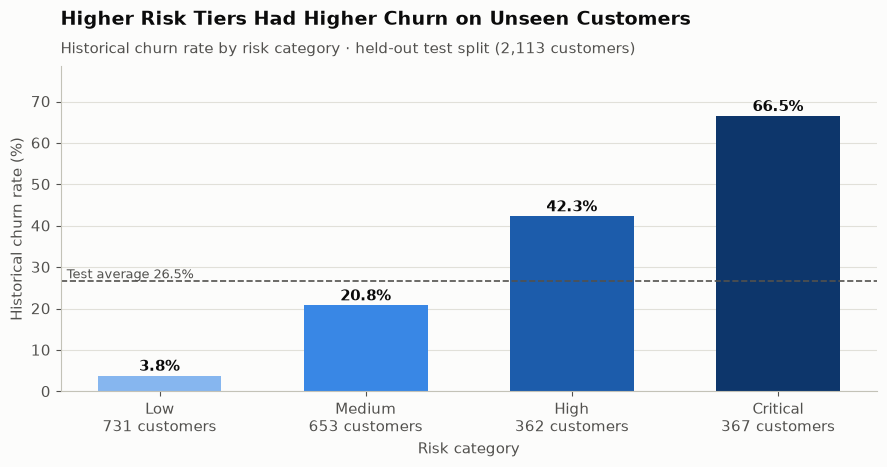

Saved outputs/visuals/07_risk_validation_holdout.png


In [16]:
# Chart 7 - Validation: historical churn rate by risk tier on the held-out test split
test_churn = sm.churn_rate_pct(test_scores["Churn"])
fig, ax = new_chart("Higher Risk Tiers Had Higher Churn on Unseen Customers",
                    f"Historical churn rate by risk category · held-out test split ({is_test.sum():,} customers)",
                    figsize=(9, 4.8))
ax.bar(sm.RISK_LABELS, tier_validation["churn_rate_pct"], color=[RISK_COLORS[t] for t in sm.RISK_LABELS], width=0.6)
for x, rate in enumerate(tier_validation["churn_rate_pct"]):
    ax.text(x, rate + 1.2, f"{rate:.1f}%", ha="center", color=INK, fontsize=10.5, fontweight="bold")
ax.set_xticks(range(4), [f"{tier}\n{n:,} customers" for tier, n in zip(sm.RISK_LABELS, tier_validation["customers"])])
reference_line(ax, test_churn, f"Test average {test_churn:.1f}%", horizontal_bars=False)
ax.set_ylabel("Historical churn rate (%)"); ax.set_xlabel("Risk category")
ax.set_ylim(0, tier_validation["churn_rate_pct"].max() * 1.18)
ax.grid(axis="y"); ax.set_axisbelow(True)
save_chart(fig, "07_risk_validation_holdout.png")

**Interpretation.** The score ranks unseen customers almost as well as it ranks the training customers, so the weights are not over-fitted. Churn rises at every step from Low to Critical, and the fitted logistic regression is only marginally better – evidence that the transparent scorecard is good enough for prioritisation.

**Important caveats.** The score shows how closely a customer *resembles* customers who churned in this snapshot. It is not a calibrated probability, and it has not been tested on future churn, because the data has no dates.

## 11. Risk Category Distribution

,customers,share_pct,avg_risk_score,historical_churn_rate_pct
risk_category,,,,
Low,2451,34.8,11.0,3.7
Medium,2156,30.6,44.2,20.0
High,1167,16.6,68.5,43.1
Critical,1269,18.0,88.2,66.4


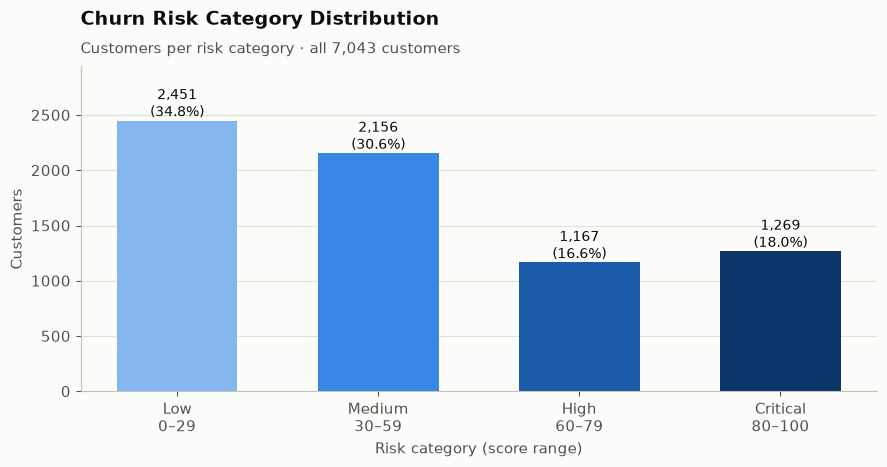

Saved outputs/visuals/03_risk_category_distribution.png


In [17]:
risk_counts = scored["risk_category"].value_counts().reindex(sm.RISK_LABELS)
risk_distribution = pd.DataFrame({
    "customers": risk_counts,
    "share_pct": (risk_counts / len(scored) * 100).round(1),
    "avg_risk_score": scored.groupby("risk_category")["risk_score"].mean().reindex(sm.RISK_LABELS).round(1),
    "historical_churn_rate_pct": scored.groupby("risk_category")["Churn"].apply(sm.churn_rate_pct).reindex(sm.RISK_LABELS).round(1),
})
display(risk_distribution)

# Chart 3 - Churn-risk category distribution
fig, ax = new_chart("Churn Risk Category Distribution",
                    f"Customers per risk category · all {len(scored):,} customers", figsize=(9, 4.8))
ax.bar(sm.RISK_LABELS, risk_distribution["customers"], color=[RISK_COLORS[t] for t in sm.RISK_LABELS], width=0.6)
for x, (count, pct) in enumerate(zip(risk_distribution["customers"], risk_distribution["share_pct"])):
    ax.text(x, count + 40, f"{count:,}\n({pct:.1f}%)", ha="center", color=INK, fontsize=10)
ax.set_xticks(range(4), [f"{t}\n{lo}–{hi}" for t, lo, hi in zip(sm.RISK_LABELS, [0, 30, 60, 80], [29, 59, 79, 100])])
ax.set_ylabel("Customers"); ax.set_xlabel("Risk category (score range)")
ax.set_ylim(0, risk_distribution["customers"].max() * 1.2)
ax.grid(axis="y"); ax.set_axisbelow(True)
save_chart(fig, "03_risk_category_distribution.png")

risk_category,Low,Medium,High,Critical
segment,,,,
New Customers,7.2,28.3,23.8,40.7
High-Value Customers,17.8,46.0,22.9,13.3
Phone-Only Basic Customers,97.2,2.8,0.0,0.0
Loyal Contract Customers,80.3,19.1,0.7,0.0
Flexible Month-to-Month Customers,5.3,52.4,26.3,16.0


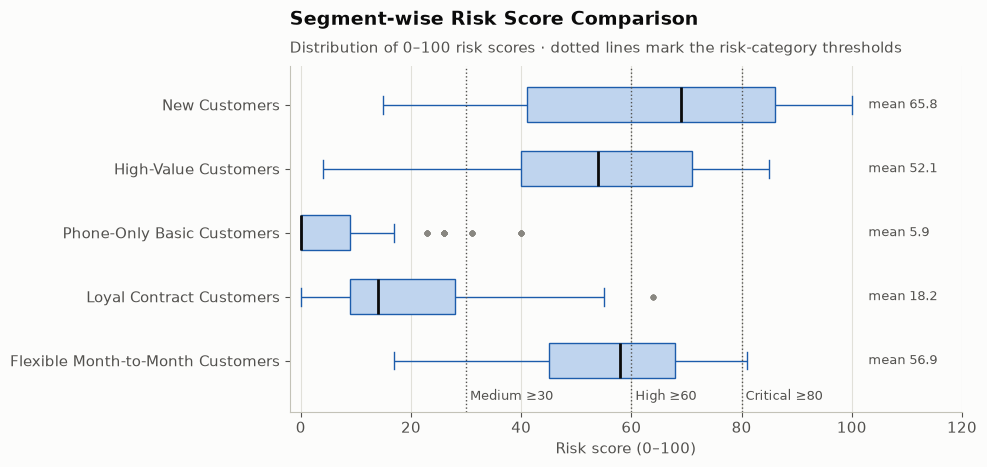

Saved outputs/visuals/06_risk_score_by_segment.png


In [18]:
# Risk tier mix within each segment (row percentages)
segment_risk_mix = (pd.crosstab(scored["segment"], scored["risk_category"], normalize="index") * 100)
segment_risk_mix = segment_risk_mix.reindex(index=sm.SEGMENT_ORDER, columns=sm.RISK_LABELS, fill_value=0).round(1)
display(segment_risk_mix)

# Chart 6 - Segment-wise risk score comparison
fig, ax = new_chart("Segment-wise Risk Score Comparison",
                    "Distribution of 0–100 risk scores · dotted lines mark the risk-category thresholds")
sns.boxplot(
    data=scored, y="segment", x="risk_score", order=sm.SEGMENT_ORDER, ax=ax, width=0.55,
    color=BOX_FILL, linecolor=BOX_EDGE, medianprops={"color": INK, "linewidth": 2},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": MUTED},
)
means = scored.groupby("segment")["risk_score"].mean()
for y, name in enumerate(sm.SEGMENT_ORDER):
    ax.text(103, y, f"mean {means[name]:.1f}", va="center", color=INK_SECONDARY, fontsize=9.5)
ax.set_ylim(len(sm.SEGMENT_ORDER) - 0.2, -0.6)  # room for threshold labels under the last box
for threshold, label in zip([30, 60, 80], ["Medium ≥30", "High ≥60", "Critical ≥80"]):
    ax.axvline(threshold, color=INK_SECONDARY, linestyle=":", linewidth=1)
    ax.text(threshold, len(sm.SEGMENT_ORDER) - 0.45, f" {label}", color=INK_SECONDARY, fontsize=9, va="center")
ax.set_xlim(-2, 120)
ax.set_xlabel("Risk score (0–100)"); ax.set_ylabel("")
ax.grid(axis="x"); ax.set_axisbelow(True)
save_chart(fig, "06_risk_score_by_segment.png")

## 12. Recommendation Engine

The engine combines two lookups:

- **Risk tier → urgency and intensity** (who to contact first and how personally).
- **Segment → content** (what the conversation or offer should be about).

Each customer therefore receives a priority (P1–P4) and an action sentence such as *"Personal retention call…  Focus: onboarding check-in, setup help and an add-on trial."* Recommendations are suggestions for the retention team to test; this analysis does not claim any particular retention uplift.

In [19]:
display(pd.DataFrame(sm.RISK_TIER_PLAYBOOK).T.rename_axis("risk_category"))
display(pd.DataFrame(sm.SEGMENT_PLAYBOOK).T[["focus", "action"]].rename_axis("segment"))

,priority,action
risk_category,,
Critical,P1 - Immediate,Personal retention call; review recent service issues and discuss suitable contract options
High,P2 - Targeted,Proactive outreach with a personalised retention offer matched to the customer's services
Medium,P3 - Engage,Engagement campaign with service-usage tips and a relevant add-on or plan offer
Low,P4 - Nurture,Loyalty and referral programme with a routine satisfaction survey
Not Scored,Review,Complete the missing account data before contacting the customer


,focus,action
segment,,
New Customers,"onboarding check-in, setup help and an add-on trial","Structured onboarding: setup help and check-ins during the first months, introduce Online Security / Tech ..."
High-Value Customers,priority support and a plan-fit review,"Relationship management: premium or priority support, a periodic plan-fit review so customers are not payi..."
Phone-Only Basic Customers,light-touch satisfaction check,"Low-cost maintenance: keep service reliable, use light-touch satisfaction surveys, and test relevant inter..."
Loyal Contract Customers,renewal reminder and loyalty recognition,"Renewal management: contact customers ahead of contract end, recognise loyalty, and invite them into a ref..."
Flexible Month-to-Month Customers,contract options and add-on bundle,"Commitment and value building: offer contract options with clear benefits, promote automatic payment, and ..."
Needs Data Review,data correction,"Correct the source record, then re-run the scoring."


In [20]:
segment_summary = sm.build_segment_summary(scored)
display(segment_summary)

# One example customer per priority level
display(
    scored.sort_values("risk_score", ascending=False)
    .groupby("retention_priority").head(1)
    [["customerID", "segment", "risk_score", "risk_category", "retention_priority", "recommended_action"]]
)

priority_list = sm.build_priority_list(scored)
print(f"Active (not churned) customers in High or Critical tiers: {len(priority_list):,}")
display(priority_list.head(10))

,segment,customer_count,customer_pct,avg_tenure_months,avg_monthly_charges,churn_rate_pct,avg_risk_score,high_or_critical_pct,main_characteristics,business_interpretation,recommended_action
0,New Customers,2186,31.04,4.7,56.10,47.44,65.8,64.55,Median tenure 4 months; 91% month-to-month; 42% fiber optic; 45% electronic check; average 1.0 add-on serv...,"Customers still forming their opinion of the service. Most are on month-to-month terms, so a poor first-ye...","Structured onboarding: setup help and check-ins during the first months, introduce Online Security / Tech ..."
1,High-Value Customers,1525,21.65,50.3,101.62,26.69,52.1,36.20,Median tenure 54 months; 42% month-to-month; 97% fiber optic; 42% electronic check; average 3.9 add-on ser...,"The highest-spending established customers, typically on fiber optic with several add-ons. Their risk depe...","Relationship management: premium or priority support, a periodic plan-fit review so customers are not payi..."
2,Phone-Only Basic Customers,1013,14.38,43.7,21.44,2.07,5.9,0.00,Median tenure 44 months; 13% month-to-month; 0% fiber optic; 7% electronic check; average 0.0 add-on services,Long-standing customers who buy only the low-cost phone plan. They are the most stable group and need litt...,"Low-cost maintenance: keep service reliable, use light-touch satisfaction surveys, and test relevant inter..."
3,Loyal Contract Customers,1221,17.34,51.8,67.59,5.65,18.2,0.66,Median tenure 56 months; 0% month-to-month; 11% fiber optic; 16% electronic check; average 3.5 add-on serv...,Established customers on fixed-term contracts with long tenure. Their main exposure is the contract renewa...,"Renewal management: contact customers ahead of contract end, recognise loyalty, and invite them into a ref..."
4,Flexible Month-to-Month Customers,1098,15.59,30.4,67.64,30.51,56.9,42.35,Median tenure 27 months; 100% month-to-month; 51% fiber optic; 44% electronic check; average 1.7 add-on se...,Customers who have stayed beyond their first year without committing to a contract. They have shown some l...,"Commitment and value building: offer contract options with clear benefits, promote automatic payment, and ..."


,customerID,segment,risk_score,risk_category,retention_priority,recommended_action
5933,6496-SLWHQ,New Customers,100.0,Critical,P1 - Immediate,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
4952,7379-FNIUJ,New Customers,77.0,High,P2 - Targeted,Proactive outreach with a personalised retention offer matched to the customer's services. Focus: onboardi...
897,0678-RLHVP,High-Value Customers,59.0,Medium,P3 - Engage,Engagement campaign with service-usage tips and a relevant add-on or plan offer. Focus: priority support a...
1802,7492-TAFJD,New Customers,29.0,Low,P4 - Nurture,"Loyalty and referral programme with a routine satisfaction survey. Focus: onboarding check-in, setup help ..."


Active (not churned) customers in High or Critical tiers: 1,090


,priority_rank,customerID,segment,risk_score,risk_category,retention_priority,tenure,Contract,MonthlyCharges,recommended_action
0,1,7145-FEJWU,New Customers,100.0,Critical,P1 - Immediate,12.0,Month-to-month,105.30,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
1,2,1960-UYCNN,New Customers,100.0,Critical,P1 - Immediate,10.0,Month-to-month,95.25,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
2,3,5150-ITWWB,New Customers,100.0,Critical,P1 - Immediate,3.0,Month-to-month,94.85,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
3,4,5168-MSWXT,New Customers,100.0,Critical,P1 - Immediate,8.0,Month-to-month,94.75,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
4,5,6350-XFYGW,New Customers,100.0,Critical,P1 - Immediate,4.0,Month-to-month,94.75,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
5,6,8161-QYMTT,New Customers,100.0,Critical,P1 - Immediate,7.0,Month-to-month,94.10,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
6,7,8087-LGYHQ,New Customers,100.0,Critical,P1 - Immediate,9.0,Month-to-month,94.05,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
7,8,3318-NMQXL,New Customers,100.0,Critical,P1 - Immediate,3.0,Month-to-month,92.00,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
8,9,4927-WWOOZ,New Customers,100.0,Critical,P1 - Immediate,2.0,Month-to-month,91.45,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...
9,10,8622-ZLFKO,New Customers,100.0,Critical,P1 - Immediate,6.0,Month-to-month,90.75,Personal retention call; review recent service issues and discuss suitable contract options. Focus: onboar...


In [21]:
# Save the deliverable CSV files (customer-level files contain no demographic fields).
customer_segments = scored[
    ["customerID", "segment", "risk_score", "risk_category", "retention_priority", "recommended_action",
     *sm.CUSTOMER_FEATURE_COLUMNS, "Churn"]
].rename(columns={"Churn": "historical_churn"})
customer_risk_scores = scored[
    ["customerID", *sm.RISK_INDICATORS, "missing_risk_inputs", "raw_risk_points", "risk_score", "risk_category"]
]
for frame in (customer_segments, customer_risk_scores, priority_list):
    if "tenure" in frame:
        frame["tenure"] = frame["tenure"].astype("Int64")
customer_risk_scores = customer_risk_scores.astype({"raw_risk_points": "Int64"})

outputs = {
    "customer_segments.csv": customer_segments,
    "segment_summary.csv": segment_summary,
    "customer_risk_scores.csv": customer_risk_scores,
    "risk_scoring_weights.csv": weights,
    "priority_retention_list.csv": priority_list,
}
for filename, frame in outputs.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)
    print(f"Saved outputs/{filename:<30} {len(frame):>6,} rows x {frame.shape[1]} columns")

Saved outputs/customer_segments.csv           7,043 rows x 17 columns
Saved outputs/segment_summary.csv                 5 rows x 11 columns
Saved outputs/customer_risk_scores.csv        7,043 rows x 13 columns
Saved outputs/risk_scoring_weights.csv            8 rows x 7 columns
Saved outputs/priority_retention_list.csv     1,090 rows x 10 columns


## 13. Business Insights

In [22]:
active = scored.loc[scored["Churn"].eq("No")]
active_priority = active["risk_category"].isin(["High", "Critical"])
exposure = active.loc[active_priority, "MonthlyCharges"].sum()
exposure_share = exposure / active["MonthlyCharges"].sum() * 100
priority_by_segment = priority_list["segment"].value_counts().reindex(sm.SEGMENT_ORDER, fill_value=0)

high_value = scored.loc[scored["segment"].eq("High-Value Customers")]
high_value_by_contract = high_value.groupby(high_value["Contract"].eq("Month-to-month").map({True: "Month-to-month", False: "One/two-year"})).agg(
    customers=("customerID", "size"), churn_rate_pct=("Churn", sm.churn_rate_pct), avg_risk_score=("risk_score", "mean"),
).round(1)
display(high_value_by_contract)

new_customers = scored.loc[scored["segment"].eq("New Customers")]
summary_lookup = segment_summary.set_index("segment")
top_weights = weights.sort_values("points", ascending=False)

insights = f'''
1. **Risk is concentrated.** {risk_distribution.loc[["High", "Critical"], "share_pct"].sum():.1f}% of all customers fall in the High or Critical tiers. On the held-out test split those tiers captured {capture:.1f}% of churners while containing {high_or_critical.mean() * 100:.1f}% of customers.
2. **Today's call list:** {len(priority_list):,} customers who have *not* churned sit in High or Critical tiers. Together they pay {exposure:,.2f} per month in charges – {exposure_share:.1f}% of the monthly charges of all active customers. This is revenue exposure, not a forecast of savings.
3. **New customers dominate the list.** {priority_by_segment["New Customers"]:,} of the {len(priority_list):,} priority customers ({priority_by_segment["New Customers"] / len(priority_list) * 100:.1f}%) are in their first year, and {summary_lookup.loc["New Customers", "high_or_critical_pct"]:.1f}% of all New Customers are High or Critical. Onboarding is where retention effort reaches the most at-risk customers.
4. **Contract type splits the High-Value segment.** High-Value customers on month-to-month terms churned at {high_value_by_contract.loc["Month-to-month", "churn_rate_pct"]:.1f}% versus {high_value_by_contract.loc["One/two-year", "churn_rate_pct"]:.1f}% for those on one- or two-year contracts. Contract offers for high-spend month-to-month customers are worth testing – but this is an association: customers who choose contracts may differ in other ways, so the gap is not a promised effect.
5. **Contract and lifecycle carry the most weight.** The heaviest indicators are {", ".join(f"{name.replace('_', ' ')} ({pts} pts)" for name, pts in zip(top_weights["indicator"].head(3), top_weights["points"].head(3)))}; high monthly charges on their own add only {int(weights.set_index("indicator").loc["high_monthly_charges", "points"])} points.
6. **Stable groups need little spend.** Phone-Only Basic ({summary_lookup.loc["Phone-Only Basic Customers", "churn_rate_pct"]:.2f}% historical churn) and Loyal Contract customers ({summary_lookup.loc["Loyal Contract Customers", "churn_rate_pct"]:.2f}%) can be served with low-cost loyalty and renewal programmes.
'''
display(Markdown(insights))

,customers,churn_rate_pct,avg_risk_score
Contract,,,
Month-to-month,647,44.0,70.4
One/two-year,878,13.9,38.7



1. **Risk is concentrated.** 34.6% of all customers fall in the High or Critical tiers. On the held-out test split those tiers captured 70.8% of churners while containing 34.5% of customers.
2. **Today's call list:** 1,090 customers who have *not* churned sit in High or Critical tiers. Together they pay 83,087.30 per month in charges – 26.2% of the monthly charges of all active customers. This is revenue exposure, not a forecast of savings.
3. **New customers dominate the list.** 539 of the 1,090 priority customers (49.4%) are in their first year, and 64.5% of all New Customers are High or Critical. Onboarding is where retention effort reaches the most at-risk customers.
4. **Contract type splits the High-Value segment.** High-Value customers on month-to-month terms churned at 44.0% versus 13.9% for those on one- or two-year contracts. Contract offers for high-spend month-to-month customers are worth testing – but this is an association: customers who choose contracts may differ in other ways, so the gap is not a promised effect.
5. **Contract and lifecycle carry the most weight.** The heaviest indicators are month to month contract (17 pts), early tenure (15 pts), electronic check payment (14 pts); high monthly charges on their own add only 4 points.
6. **Stable groups need little spend.** Phone-Only Basic (2.07% historical churn) and Loyal Contract customers (5.65%) can be served with low-cost loyalty and renewal programmes.


In [23]:
# Record the headline numbers so the memo and README can be checked against them.
metrics = {
    "dataset": {"customers": int(len(scored)), "historical_churn_rate_pct": round(overall_churn, 2)},
    "split": {"seed": sm.RANDOM_SEED, "train_customers": int(len(train_index)), "test_customers": int(len(test_index))},
    "validation": {
        "auc_train": round(auc_train, 4), "auc_test": round(auc_test, 4),
        "benchmark_logistic_regression_auc_test": round(benchmark_auc, 4),
        "tiers_monotonic_on_test": bool(monotonic),
        "test_share_high_or_critical_pct": round(high_or_critical.mean() * 100, 2),
        "test_churn_capture_high_or_critical_pct": round(capture, 2),
        "test_tier_churn": tier_validation.reset_index().to_dict("records"),
    },
    "kmeans_silhouette": {str(k): v for k, v in silhouette.items()},
    "risk_distribution": risk_distribution.reset_index().to_dict("records"),
    "segment_summary": segment_summary.drop(columns=["business_interpretation", "recommended_action"]).to_dict("records"),
    "high_value_by_contract": high_value_by_contract.reset_index().to_dict("records"),
    "priority_list": {
        "active_high_or_critical_customers": int(len(priority_list)),
        "by_segment": priority_by_segment.to_dict(),
        "by_tier": priority_list["risk_category"].value_counts().to_dict(),
        "monthly_charges_exposure": round(exposure, 2),
        "share_of_active_monthly_charges_pct": round(exposure_share, 2),
        "active_customers": int(len(active)),
    },
    "weights": weights[["indicator", "lift_pp", "points"]].to_dict("records"),
}
(OUTPUT_DIR / "task04_metrics.json").write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
print("Saved outputs/task04_metrics.json")

Saved outputs/task04_metrics.json


## 14. Edge Case Validation

The pipeline is tested with deliberately problematic records: missing and repeated IDs, missing numbers and categories, zero tenure, zero and extreme charges, unknown labels, empty inputs and customers with too little information. The same function writes `reports/edge_case_validation.md`.

In [24]:
edge_results = edge_cases.run_edge_case_checks(raw, weights)
display(edge_results[["id", "test_case", "expected", "actual", "status"]])
report_path = edge_cases.write_report(edge_results)
print(f"{edge_results['status'].eq('PASS').sum()} of {len(edge_results)} checks passed "
      f"-> {report_path.relative_to(PROJECT_ROOT)}")
assert edge_results["status"].eq("PASS").all()

,id,test_case,expected,actual,status
0,EC01,Missing customer IDs,Both records without an ID are dropped and logged; the valid customer is scored.,"1 customer kept, 2 records dropped and logged",PASS
1,EC02,Duplicate customer records,"First EDGE-01 record kept, the two repeats dropped and logged; 2 customers scored.","2 customers kept, 2 repeats dropped, EDGE-01 tenure kept = 1",PASS
2,EC03,Missing numerical values,EDGE-01 is still segmented and scored with the high-charge flag off; EDGE-02 goes to 'Needs Data Review' a...,"EDGE-01: Flexible Month-to-Month Customers, score 68.0, high-charge flag 0; EDGE-02: Needs Data Review, No...",PASS
3,EC04,Missing categorical values,Customer is still scored; flags that depend on the blank fields stay 0; missing_risk_inputs = 2.,"New Customers, score 41.0, dependent flags {'electronic_check_payment': 0, 'fiber_optic_service': 0, 'no_o...",PASS
4,EC05,Zero tenure,"Segment 'New Customers', early-tenure flag on, valid score; no division by zero.","New Customers, early_tenure = 1, score 83.0",PASS
5,EC06,Zero monthly charges,"Record kept and scored, high-charge flag off, data-quality note asks to verify billing.","Flexible Month-to-Month Customers, score 68.0, note: 'zero monthly charge'",PASS
6,EC07,Very high monthly charges,"Record kept, high-charge flag on, score still capped at 100, note flags the value for review.","High-Value Customers, score 85.0, note: 'monthly charge above plausible range'",PASS
7,EC08,Unexpected categorical values,Case/space variants are standardised; unknown contract -> 'Needs Data Review'; unknown payment method -> m...,EDGE-01 contract -> 'Month-to-month'; EDGE-02 -> Needs Data Review; EDGE-03 payment -> missing (scored: Tr...,PASS
8,EC09,Empty datasets,Each returns zero scored customers and empty summary / priority tables without raising.,"Rows returned (scored + summary + priority) per input: [0, 0, 0]",PASS
9,EC10,Customers with insufficient information,"Both are routed to 'Needs Data Review', 'Not Scored', with a data-correction action.","2 customers -> [{'segment': 'Needs Data Review', 'risk_category': 'Not Scored', 'retention_priority': 'Rev...",PASS


17 of 17 checks passed -> reports/edge_case_validation.md


## 15. Final Conclusion

This notebook turns the descriptive churn analysis into a **reproducible prioritisation tool**:

- **Segmentation:** five explainable, rule-based segments that never use the churn outcome. K-Means was evaluated and rejected because it found only moderately separated groups and would be harder to explain.
- **Risk scoring:** an eight-indicator points scorecard (0–100). Its weights were set on a training split, and on unseen customers it ranks churners clearly above non-churners, with churn rising across every tier. A logistic regression on the same inputs is only marginally better.
- **Recommendations:** each customer receives a priority (P1–P4) and an action that combines risk urgency with segment-specific content, plus a ranked list of active High/Critical customers.
- **Robustness:** edge cases are handled without crashes, scores always stay within 0–100, and every valid customer receives exactly one segment.

**Limitations.** The data is a single public snapshot (not EdVyro data) with no dates, so the score measures resemblance to past churners rather than a time-bound forecast. Indicator weights come from single-indicator lifts, so related indicators (for example fiber service and missing add-ons) partly overlap. Recommendations are hypotheses to test, ideally with a control group, before any retention uplift is claimed.

**Outputs:** `outputs/customer_segments.csv`, `outputs/segment_summary.csv`, `outputs/customer_risk_scores.csv`, `outputs/risk_scoring_weights.csv`, `outputs/priority_retention_list.csv`, `outputs/task04_metrics.json`, charts in `outputs/visuals/`, and the reports `reports/recommendation_memo.md` and `reports/edge_case_validation.md`.

In [25]:
generated = sorted(p for p in OUTPUT_DIR.rglob("*") if p.is_file())
display(pd.DataFrame({
    "file": [str(p.relative_to(PROJECT_ROOT)) for p in generated],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in generated],
}))

,file,size_kb
0,outputs/customer_risk_scores.csv,293.5
1,outputs/customer_segments.csv,1822.4
2,outputs/priority_retention_list.csv,244.6
3,outputs/risk_scoring_weights.csv,0.8
4,outputs/segment_summary.csv,2.7
5,outputs/task04_metrics.json,5.4
6,outputs/visuals/01_segment_distribution.png,62.8
7,outputs/visuals/02_churn_rate_by_segment.png,65.8
8,outputs/visuals/03_risk_category_distribution.png,58.5
9,outputs/visuals/04_avg_monthly_charges_by_segment.png,67.4
